# 03 · Logistic regression baseline

**Financial Fraud Detection Using Machine Learning and Deep Learning**

This notebook establishes the simple machine-learning reference model specified in the project proposal. It trains on PaySim and evaluates on a **validation set**; the test partition is reserved for a later, consistent comparison across models.

### What this notebook does

1. Checks the dataset fingerprint and creates a reproducible stratified 70% / 15% / 15% split.
2. Fits encoding and scaling on the training data only, then trains logistic regression.
3. Reports validation average precision (AP), ROC-AUC and metrics at the default threshold and an F1-selected validation threshold.
4. Saves the fitted pipeline and settings as a small checkpoint for future use.

**Scope and limitations:** The earlier exploratory notebook summarized the entire dataset, including data now assigned to the test partition. Therefore the test partition has not been used for model fitting or threshold tuning, but it is *not fully blinded* to the preceding aggregate exploration. This random split is a research baseline, not evidence of performance on future transactions, unseen accounts or real payment networks. A chronological and/or account-aware evaluation is needed for those questions. PaySim is synthetic.

**Run:** select the project `.venv (Python 3.15.2)` kernel and choose **Run All**. Full-data training can take several minutes.

**Research context:** [Fraud Detection in Mobile Payment Systems using an XGBoost-based Framework](https://pmc.ncbi.nlm.nih.gov/articles/PMC9560719/) uses PaySim to study fraud classification and imbalance. Our logistic-regression reference and its split are our own; this is not an exact reproduction and the reported numbers should not be compared as if the protocols were identical.

In [1]:
from pathlib import Path
import hashlib, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "data" / "README.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within the project folder.")
DATA_PATH = ROOT / "data/raw/PS_20174392719_1491204439457_log.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset missing: {DATA_PATH}; see data/README.md.")
SEED = 42
EXPECTED_SHA256 = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
NUMERIC = ["step", "amount", "oldbalanceOrg", "oldbalanceDest"]
CATEGORICAL = ["type"]
FEATURES = NUMERIC + CATEGORICAL
print("Dataset:", DATA_PATH.relative_to(ROOT).as_posix())
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Dataset: data/raw/PS_20174392719_1491204439457_log.csv
Python 3.15.2 | pandas 3.1.1 | NumPy 2.5.4 | scikit-learn 1.9.1


## 1. Dataset integrity and prediction point

The intended prediction point is **before a transaction is completed**. The baseline uses transaction step, type, amount and the origin/destination balances before the transaction. We assume both balances are available at scoring time; real payment systems may not provide destination balances. Account IDs, post-transaction balances and `isFlaggedFraud` are excluded.

The `step` feature may capture simulator-specific time patterns, and even pre-transaction balances may reflect synthetic-data artifacts. We will investigate these assumptions in later ablations.

In [2]:
digest = hashlib.sha256()
with DATA_PATH.open("rb") as stream:
    for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
        digest.update(block)
actual_sha256 = digest.hexdigest()
print("Dataset SHA-256:", actual_sha256)
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("Dataset fingerprint differs from the project copy; verify the input before comparing results.")

dtypes = {"step": "int16", "type": "category", "amount": "float32",
          "oldbalanceOrg": "float32", "oldbalanceDest": "float32", "isFraud": "int8"}
df = pd.read_csv(DATA_PATH, usecols=FEATURES + ["isFraud"], dtype=dtypes)
if df[FEATURES + ["isFraud"]].isna().any().any():
    raise ValueError("Missing inputs found; inspect data and add a train-fitted imputation strategy.")
if set(df["isFraud"].unique()) != {0, 1}:
    raise ValueError("Expected binary target values 0 and 1.")
print(f"Transactions: {len(df):,} | Fraud: {int(df.isFraud.sum()):,}")
print("Training inputs:", FEATURES)

Dataset SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


Transactions: 6,362,620 | Fraud: 8,213
Training inputs: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'type']


## 2. Fixed stratified split

We split **row indices** using seed 42: 70% training, 15% validation and 15% test, preserving the class proportions approximately. The test partition is not used in this notebook for fitting, threshold selection or performance measurement. Later models must reproduce the same dataset fingerprint, row order, split procedure, seed and package versions for a fair comparison.

Because the split is random at the transaction level, related accounts or later timestamps can appear across partitions. Results should not be interpreted as a chronological or account-disjoint evaluation.

In [3]:
y = df["isFraud"].to_numpy(copy=True)
row_ids = np.arange(len(df))
train_ids, holdout_ids = train_test_split(row_ids, test_size=0.30, random_state=SEED, stratify=y)
val_ids, test_ids = train_test_split(holdout_ids, test_size=0.50, random_state=SEED, stratify=y[holdout_ids])
del row_ids, holdout_ids
assert len(train_ids) + len(val_ids) + len(test_ids) == len(df)
assert len(np.intersect1d(train_ids, val_ids)) == 0
assert len(np.intersect1d(train_ids, test_ids)) == 0
assert len(np.intersect1d(val_ids, test_ids)) == 0
split_table = pd.DataFrame([
    {"partition": name, "transactions": len(ids), "fraud": int(y[ids].sum()),
     "fraud_rate_percent": 100 * float(y[ids].mean())}
    for name, ids in [("Train", train_ids), ("Validation", val_ids), ("Test (reserved)", test_ids)]
]).set_index("partition")
display(split_table)

,transactions,fraud,fraud_rate_percent
partition,,,
Train,4453834,5749,0.129080
Validation,954393,1232,0.129087
Test (reserved),954393,1232,0.129087


## 3. Train the reference model

The pipeline learns numeric standardization and transaction-type one-hot encoding **from training rows only**. It then fits L2-regularized logistic regression with no class weighting or resampling. This is a deliberately simple baseline; imbalance handling and other models will be compared in later experiments.

The destination pre-balance and simulator clock are assumptions, not universally available real-time features.

In [4]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("type", OneHotEncoder(handle_unknown="ignore", dtype=np.float32, sparse_output=False), CATEGORICAL),
], remainder="drop", sparse_threshold=0)
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(solver="lbfgs", max_iter=200, random_state=SEED)),
])
start = time.perf_counter()
with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=4):
    warnings.simplefilter("always", ConvergenceWarning)
    model.fit(df.iloc[train_ids][FEATURES], y[train_ids])
fit_seconds = time.perf_counter() - start
convergence_warnings = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
if convergence_warnings:
    raise RuntimeError("Logistic regression did not converge: " + " | ".join(convergence_warnings))
print(f"Training finished in {fit_seconds:.1f} seconds.")
print("Iterations:", model.named_steps["classifier"].n_iter_.tolist())

Training finished in 5.7 seconds.
Iterations: [20]


## 4. Validation: score ranking and thresholds

Average precision (AP) is the step-wise summary of the precision–recall curve, and is reported here as the project's PR-curve summary. It is not identical to trapezoidal PR-AUC. ROC-AUC is included as a secondary metric. The no-skill AP reference is approximately the validation fraud prevalence.

The second threshold maximizes F1 **on this same validation set**. Its reported validation F1 is therefore an optimistic selection result, not an unbiased final estimate. Neither it nor the default-threshold metrics are test-set results.

In [5]:
validation_x = df.iloc[val_ids][FEATURES]
y_val = y[val_ids]
with threadpool_limits(limits=4):
    val_scores = model.predict_proba(validation_x)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_scores)
f1_values = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
                      out=np.zeros_like(thresholds), where=(precision[:-1] + recall[:-1]) != 0)
best_idx = int(np.argmax(f1_values))
selected_threshold = float(thresholds[best_idx])
ap = float(average_precision_score(y_val, val_scores))
roc_auc = float(roc_auc_score(y_val, val_scores))
print(f"Validation average precision (AP): {ap:.5f}")
print(f"Validation ROC-AUC: {roc_auc:.5f}")
print(f"Validation fraud prevalence: {y_val.mean():.5%}")
print(f"Validation-selected F1 threshold: {selected_threshold:.6f}")

def threshold_metrics(threshold):
    prediction = val_scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
    return {"threshold": threshold, "precision": precision_score(y_val, prediction, zero_division=0),
            "recall": recall_score(y_val, prediction, zero_division=0),
            "F1": f1_score(y_val, prediction, zero_division=0), "false_positives": int(fp),
            "false_negatives": int(fn), "alerts": int(fp + tp),
            "alert_rate_percent": 100 * (fp + tp) / len(y_val)}
results = pd.DataFrame([threshold_metrics(.5), threshold_metrics(selected_threshold)],
                       index=["Default (0.50)", "F1 selected on validation"])
display(results)

Validation average precision (AP): 0.17807
Validation ROC-AUC: 0.93170
Validation fraud prevalence: 0.12909%
Validation-selected F1 threshold: 0.068119


,threshold,precision,recall,F1,false_positives,false_negatives,alerts,alert_rate_percent
Default (0.50),0.500000,0.900990,0.073864,0.136534,10,1141,101,0.010583
F1 selected on validation,0.068119,0.242272,0.235390,0.238781,907,942,1197,0.125420


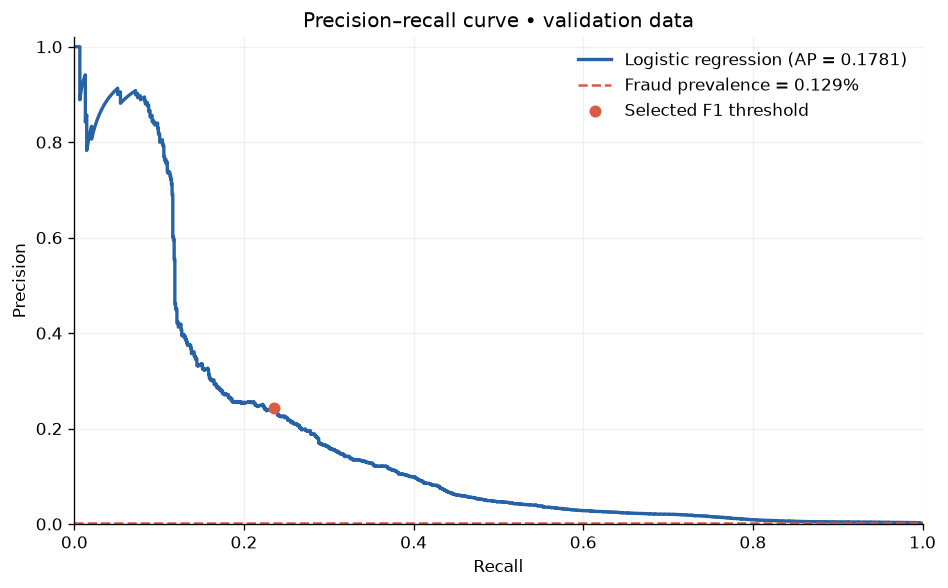

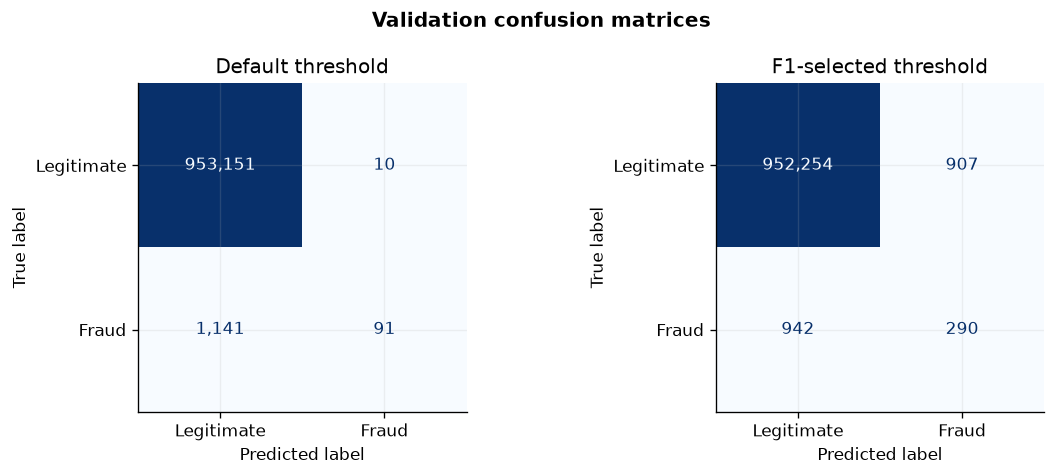

In [6]:
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall, precision, color="#2563a6", lw=2, label=f"Logistic regression (AP = {ap:.4f})")
ax.axhline(y_val.mean(), color="#d95b43", ls="--", label=f"Fraud prevalence = {y_val.mean():.3%}")
ax.scatter(recall[best_idx], precision[best_idx], s=38, color="#d95b43", zorder=3, label="Selected F1 threshold")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve • validation data", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, threshold) in zip(axes, [("Default threshold", .5), ("F1-selected threshold", selected_threshold)]):
    matrix = confusion_matrix(y_val, val_scores >= threshold, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",")
    ax.set_title(title)
fig.suptitle("Validation confusion matrices", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Save a reproducible checkpoint

The checkpoint contains the fitted preprocessing/model pipeline, the validation-selected threshold, the feature list, split procedure, data fingerprint and package versions. Only load checkpoints from trusted sources: joblib files can execute code when loaded.

The saved model is a baseline, not a deployed fraud-detection system. Final test evaluation and a proper reproducibility declaration remain for later.

In [7]:
checkpoint_path = ROOT / "models" / "logistic_regression_baseline.joblib"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
checkpoint = {"pipeline": model, "threshold": selected_threshold, "threshold_selection": "max F1 on validation",
              "features": FEATURES, "seed": SEED, "split": "stratified 70/15/15, two train_test_split calls",
              "dataset_sha256": actual_sha256, "validation_ap": ap, "validation_roc_auc": roc_auc,
              "python_version": sys.version.split()[0], "numpy_version": np.__version__,
              "pandas_version": pd.__version__, "sklearn_version": sklearn.__version__}
joblib.dump(checkpoint, checkpoint_path, compress=3)
print(f"Saved: {checkpoint_path.relative_to(ROOT).as_posix()} ({checkpoint_path.stat().st_size:,} bytes)")
print("The test partition was not scored in this notebook.")

Saved: models/logistic_regression_baseline.joblib (1,907 bytes)
The test partition was not scored in this notebook.


## Next steps

Compare the remaining models from the PDF on the **same split and prediction-point assumptions**. Investigate class weights or resampling, simulator-time and balance-feature ablations, and a chronological or account-aware evaluation. Choose the final model and threshold on training/validation data before any final test-set performance measurement.